# 13 — Generalisation on the blank sheet (step 9c)

Notebook 12: trained on the 10 letters, the agent draws them perfectly but fails on the 16 others (0 %).
Here we apply the remedy of notebook 09: **train on random figures only** and test on the letters.

- **Same agent, same settings** as notebook 12 (convolutional Double DQN, egocentric 41 × 41 view, learning rate
  0.0001, target network every 5,000 steps, gradient clipping at 10): only the training targets change.
- **Training targets**: a new random figure at each episode (`src/figures.py`, the generator of step 7c: 1 to 3
  strokes made of straight runs, 4 to 14 segments), drawn on the 28 × 28 canvas. Figures identical to one of the 26
  letters are rejected: **all 26 letters are unseen**, including the 10 letters of the project.
- **Which network do we keep?** Learning oscillates, so the network is saved at each evaluation and we keep the
  one that draws best a **validation set of 50 random figures** never used for training (the same as in
  notebook 09). The letters are never used to choose the network: they stay a true test set.

| Parameter | Value |
|---|---|
| training targets | random figures (a new one at each episode, random natural start) |
| steps | 2,000,000 (evaluation every 50,000) |
| ε | 1 → 0.05 over the first 30 % of the steps |
| other settings | as in notebook 12 |
| validation / test | 50 held-out random figures / the 26 letters |

Figures in the report style (`src/report_style.py`).

In [1]:
import sys
sys.path.insert(0, "..")

import os
import numpy as np
import matplotlib.pyplot as plt
import torch
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

from src.letters import TRAINING_LETTERS, TEST_LETTERS
from src.figures import random_figure
from src.free_draw import FreeDrawEnv
from src.free_dqn import ConvQNetwork, train_free_dqn, greedy_free_episode, EGO
from src import report_style as rs

rs.apply()
GAMMA = 0.99
RETRAIN = False   # True: train again on random figures (5-6 hours on a laptop CPU)
ALL = TRAINING_LETTERS + TEST_LETTERS
fig_rng = np.random.default_rng(12345)
held_out = [random_figure(fig_rng) for _ in range(50)]   # validation: 50 random figures never used for training

## 1. What the agent trains on

16 examples of random figures on the canvas (white rings: natural starting points = the ends of the strokes).

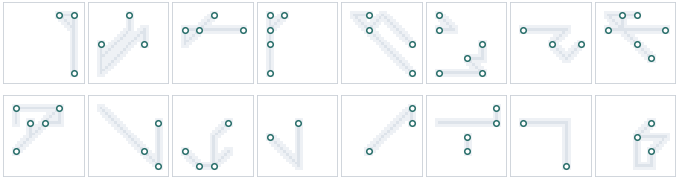

In [2]:
examples = [random_figure(np.random.default_rng(i)) for i in range(16)]
fig, axes = rs.panel_grid(16, 8, panel=0.85)
for ax, figure in zip(axes, examples):
    env = FreeDrawEnv(figure)
    rs.draw_canvas(ax, env.target, env.zone, [])
    for r, c in env.start_pixels:
        ax.plot(c, r, "o", ms=4, mfc="white", mec=rs.TEAL, mew=1.1)
fig.tight_layout(pad=0.3)
fig.savefig("../results/13_random_figures.png")
plt.show()

## 2. Training

The network and its curves are loaded from `results/13_free_dqn_figures_*` (trained by the script of step 9c).
If they are missing, or if `RETRAIN = True`, they are recomputed here (5–6 hours).

training time: 8.9 h   -   network kept: step 1,550,000


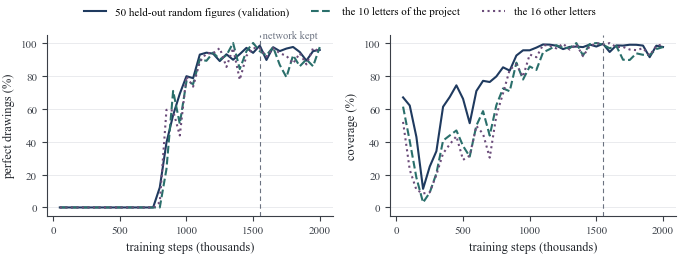

In [3]:
PREFIX = "../results/13_free_dqn_figures"
METRICS = ("coverage", "precision", "perfect", "stopped")
if RETRAIN or not (os.path.exists(PREFIX + "_best.pt") and os.path.exists(PREFIX + "_curves.npz")):
    log, best = {"steps": [], "letters": [], "figures": []}, {"perfect": -1.0, "step": 0}

    def save_curves(**extra):
        np.savez(PREFIX + "_curves.npz", eval_steps=np.array(log["steps"]), letters=np.array(ALL), best_step=best["step"],
                 **{f"letters_{m}": np.array([[r[n][m] for n in ALL] for r in log["letters"]]) for m in METRICS},
                 **{f"figures_{m}": np.array([[v[m] for v in r.values()] for r in log["figures"]]) for m in METRICS},
                 **extra)

    def callback(step, net, res, res_fig):   # save the last network, the best one on the held-out figures, the curves
        log["steps"].append(step); log["letters"].append(res); log["figures"].append(res_fig)
        torch.save(net.state_dict(), PREFIX + "_last.pt")
        fig_perfect = float(np.mean([v["perfect"] for v in res_fig.values()]))
        if fig_perfect >= best["perfect"]:
            best.update(perfect=fig_perfect, step=step)
            torch.save(net.state_dict(), PREFIX + "_best.pt")
        save_curves()

    res = train_free_dqn(None, task_sampler=random_figure, eval_letters=ALL, eval_figures=held_out, callback=callback,
                         total_steps=2_000_000, lr=1e-4, target_update=5_000, buffer_size=200_000, eps_fraction=0.3,
                         grad_clip=10.0, double=True, egocentric=True, eval_every=50_000, seed=0)
    save_curves(episode_returns=res["episode_returns"], time=res["time"])

curves = np.load(PREFIX + "_curves.npz")
best_step = int(curves["best_step"])
net = ConvQNetwork(input_size=EGO)
net.load_state_dict(torch.load(PREFIX + "_best.pt"))
net.eval()
hours = f"{float(curves['time']) / 3600:.1f} h" if "time" in curves.files else "(run not finished)"
print(f"training time: {hours}   -   network kept: step {best_step:,}")

steps = curves["eval_steps"] / 1000
n_train = len(TRAINING_LETTERS)
series = [("50 held-out random figures (validation)", "figures", slice(None), rs.NAVY, "-"),
          ("the 10 letters of the project", "letters", slice(0, n_train), rs.TEAL, "--"),
          ("the 16 other letters", "letters", slice(n_train, None), rs.PLUM, ":")]
fig, axes = plt.subplots(1, 2, figsize=(rs.WIDTH, 2.5))
for ax, metric, ylabel in zip(axes, ["perfect", "coverage"], ["perfect drawings (%)", "coverage (%)"]):
    for label, group, cols, color, ls in series:
        ax.plot(steps, 100 * curves[f"{group}_{metric}"][:, cols].mean(1), color=color, ls=ls, lw=1.5, label=label)
    ax.axvline(best_step / 1000, color=rs.SLATE, lw=0.8, ls=(0, (4, 3)))
    ax.set_ylim(-5, 105)
    rs.axes_style(ax, "training steps (thousands)", ylabel)
axes[0].text(best_step / 1000, 102, " network kept", color=rs.SLATE, fontsize=7.5, va="bottom")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout()
fig.savefig("../results/13_learning_curves.png")
plt.show()

## 3. The 26 letters, never seen during training

Greedy policy of the network kept, from every natural starting point of every letter.

letter   coverage  precision  perfect   STOP    (mean over the natural starting points)
I            100%       100%     100%   100%
L            100%       100%     100%   100%
T            100%       100%     100%   100%
E            100%       100%     100%   100%
F            100%       100%     100%   100%
H            100%       100%     100%   100%
N            100%       100%     100%   100%
Z            100%       100%     100%   100%
V            100%       100%     100%   100%
X             89%       100%      50%    50%
--------------------------------------------
A             87%       100%      50%    50%
B            100%       100%     100%   100%
C            100%       100%     100%   100%
D             99%       100%     100%   100%
G            100%       100%     100%   100%
J            100%       100%     100%   100%
K            100%       100%     100%   100%
M            100%       100%     100%   100%
O            100%       100%     100%   100%
P           

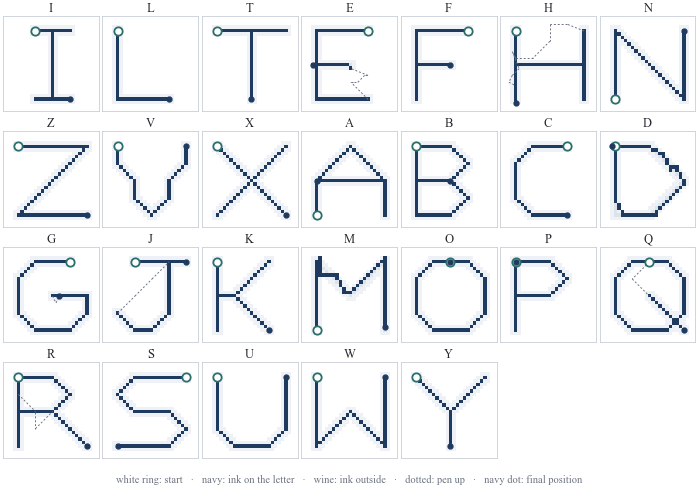

In [4]:
def play_all(model, targets):
    out = {}
    for i, target in enumerate(targets):
        env = FreeDrawEnv(target)
        key = target if isinstance(target, str) else f"figure {i}"
        out[key] = (env, [greedy_free_episode(model, env, s, GAMMA, egocentric=True) for s in env.start_pixels])
    return out

def mean_of(results, metric):
    return np.mean([np.mean([e[metric] for e in eps]) for _, eps in results.values()])

letter_eps = play_all(net, ALL)
print(f"{'letter':<7}{'coverage':>10}{'precision':>11}{'perfect':>9}{'STOP':>7}    (mean over the natural starting points)")
for name, (env, eps) in letter_eps.items():
    if name == TEST_LETTERS[0]:
        print("-" * 44)
    print(f"{name:<7}{np.mean([e['coverage'] for e in eps]):>10.0%}{np.mean([e['precision'] for e in eps]):>11.0%}"
          f"{np.mean([e['perfect'] for e in eps]):>9.0%}{np.mean([e['stopped'] for e in eps]):>7.0%}")
for label, names in [("10 letters of the project", TRAINING_LETTERS), ("16 other letters", TEST_LETTERS), ("all 26 letters", ALL)]:
    part = {n: letter_eps[n] for n in names}
    print(f"{label:<26} perfect {mean_of(part, 'perfect'):.0%}   coverage {mean_of(part, 'coverage'):.0%}   precision {mean_of(part, 'precision'):.0%}")

fig, axes = rs.panel_grid(26, 7, panel=1.0)
for ax, (name, (env, eps)) in zip(axes, letter_eps.items()):
    e = eps[0]
    rs.draw_canvas(ax, env.target, env.zone, e["history"], name if e["perfect"] else f"{name} (failed)")
rs.add_caption_line(fig, rs.CANVAS_LEGEND)
fig.tight_layout(pad=0.3)
fig.savefig("../results/13_drawings_26_letters.png")
plt.show()

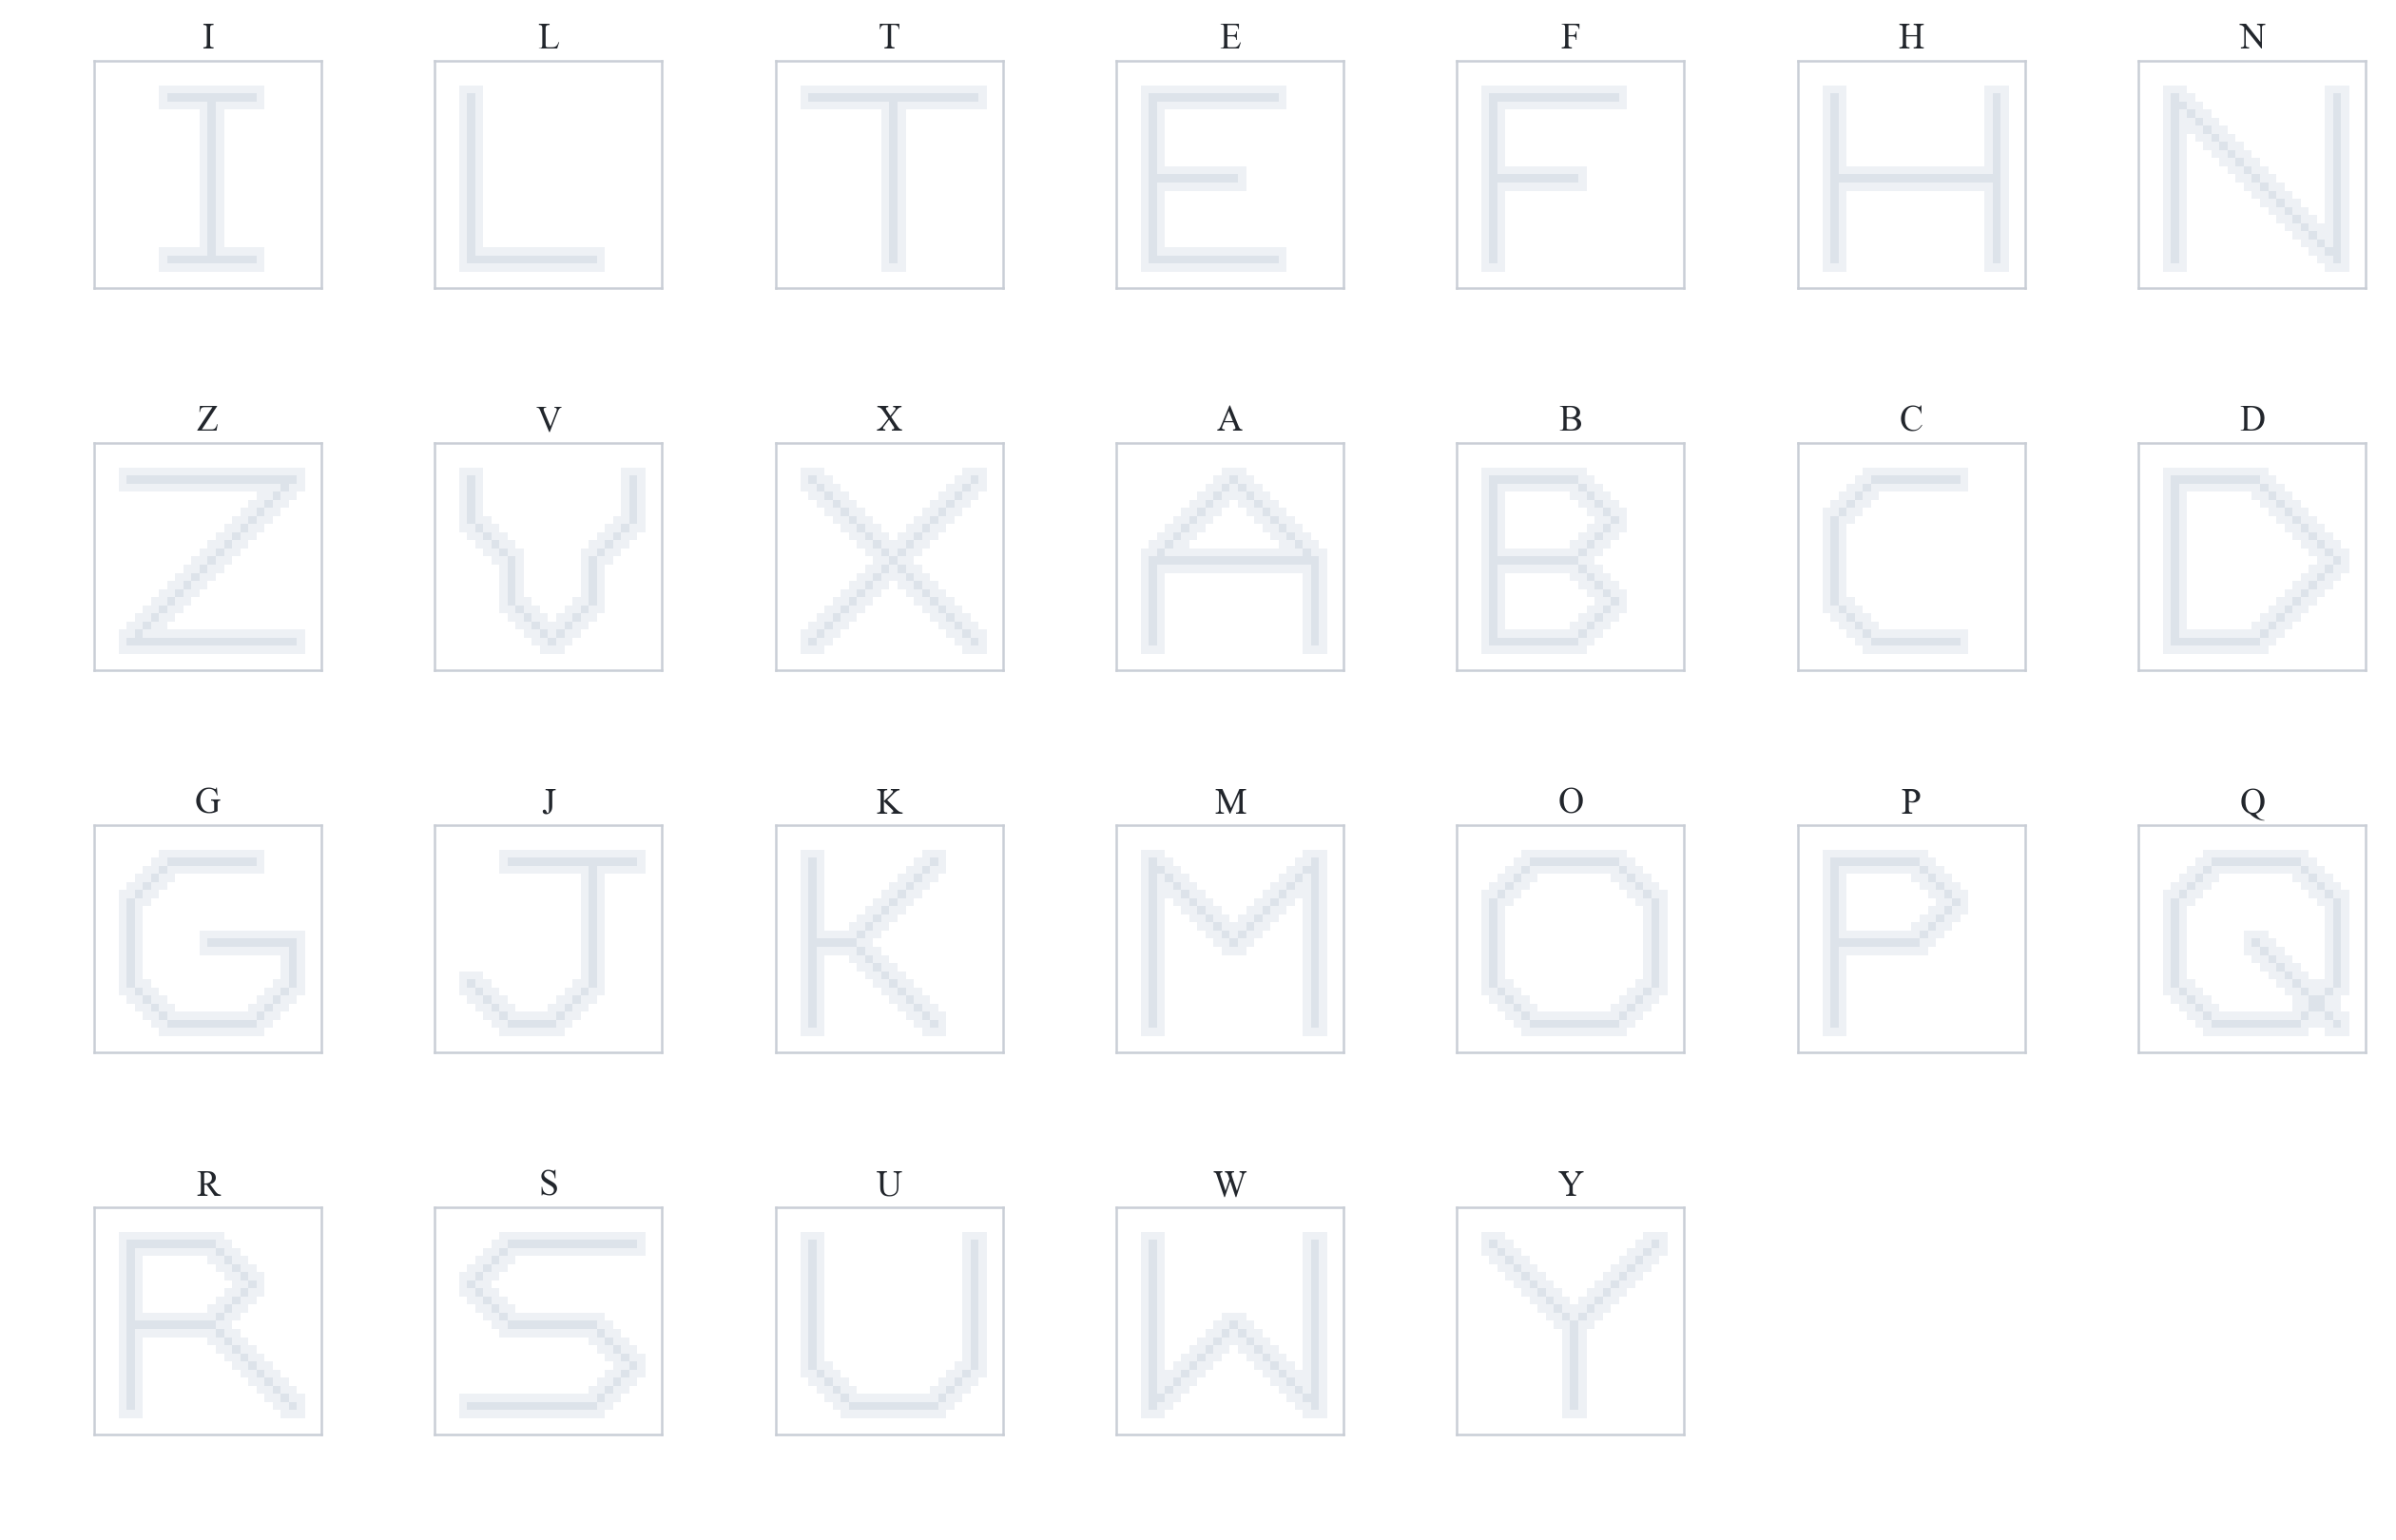

In [5]:
def animate_canvas(items, path, ncols=7, fps=5):
    """GIF of several drawings played step by step. items = list of (env, history, title)."""
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 1.2, nrows * 1.35))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[len(items):]:
        ax.axis("off")
    n = max(len(h) for _, h, _ in items) + 1

    def update(f):
        for ax, (env, h, title) in zip(axes, items):
            ax.clear()
            rs.draw_canvas(ax, env.target, env.zone, h[:min(f, len(h))], title)
        return []
    fig.tight_layout(pad=0.3)
    FuncAnimation(fig, update, frames=list(range(n)) + [n - 1] * 2 * fps).save(path, writer=PillowWriter(fps=fps))
    plt.close(fig)

animate_canvas([(env, eps[0]["history"], name) for name, (env, eps) in letter_eps.items()], "../results/13_drawings_26_letters.gif")
Image(filename="../results/13_drawings_26_letters.gif")

## 4. Trained on 10 letters or on random figures?

The network of notebook 12 (trained on the 10 letters) against the network of this notebook (trained on random
figures only), on three sets of targets.

trained on the 10 letters (notebook 12)
    10 letters of the project perfect 100.0 %   coverage 100.0 %
    16 other letters         perfect   0.0 %   coverage  21.1 %
    50 random figures        perfect   8.2 %   coverage  54.3 %
trained on random figures only (this notebook)
    10 letters of the project perfect  95.0 %   coverage  98.9 %
    16 other letters         perfect  96.9 %   coverage  99.1 %
    50 random figures        perfect  98.4 %   coverage  99.5 %


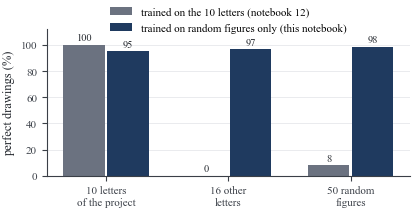

In [6]:
net12 = ConvQNetwork(input_size=EGO)
net12.load_state_dict(torch.load("../results/12_free_dqn_10letters.pt"))
net12.eval()
letters12 = play_all(net12, ALL)
subset = lambda results, names: {n: results[n] for n in names}
set_labels = ["10 letters\nof the project", "16 other\nletters", "50 random\nfigures"]
runs = {"trained on the 10 letters (notebook 12)":
            [subset(letters12, TRAINING_LETTERS), subset(letters12, TEST_LETTERS), play_all(net12, held_out)],
        "trained on random figures only (this notebook)":
            [subset(letter_eps, TRAINING_LETTERS), subset(letter_eps, TEST_LETTERS), play_all(net, held_out)]}
scores = {}
for label, parts in runs.items():
    scores[label] = [(100 * mean_of(r, "perfect"), 100 * mean_of(r, "coverage")) for r in parts]
    print(label)
    for set_label, (p, c) in zip(set_labels, scores[label]):
        print(f"    {set_label.replace(chr(10), ' '):<24} perfect {p:5.1f} %   coverage {c:5.1f} %")

fig, ax = plt.subplots(figsize=(rs.WIDTH * 0.62, 2.4))
x = np.arange(len(set_labels))
for k, ((label, vals), color) in enumerate(zip(scores.items(), [rs.SLATE, rs.NAVY])):
    perfect = [p for p, _ in vals]
    bars = ax.bar(x + (k - 0.5) * 0.36, perfect, 0.34, color=color, label=label)
    for b, v in zip(bars, perfect):
        ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f"{v:.0f}", ha="center", va="bottom", fontsize=7.5, color=rs.TEXT)
ax.set_xticks(x, set_labels)
ax.set_ylim(0, 112)
rs.axes_style(ax, None, "perfect drawings (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.22), ncol=1)
fig.tight_layout()
fig.savefig("../results/13_comparison.png")
plt.show()

## 5. The failures

Every episode (letter, starting point) that is not a perfect drawing.

3 failed episodes out of 66
  X, start 2: coverage 78%, precision 100%, no STOP (60-step limit), 60 steps
  X, start 4: coverage 78%, precision 100%, no STOP (60-step limit), 60 steps
  A, start 2: coverage 73%, precision 100%, no STOP (60-step limit), 60 steps


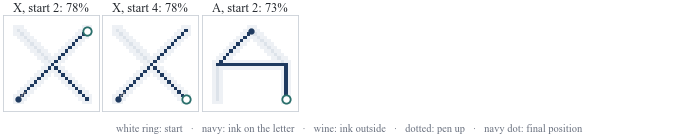

In [7]:
failures = [(name, k, env, e) for name, (env, eps) in letter_eps.items() for k, e in enumerate(eps) if not e["perfect"]]
n_episodes = sum(len(eps) for _, eps in letter_eps.values())
print(f"{len(failures)} failed episodes out of {n_episodes}")
for name, k, env, e in failures:
    print(f"  {name}, start {k + 1}: coverage {e['coverage']:.0%}, precision {e['precision']:.0%}, "
          f"{'STOP' if e['stopped'] else 'no STOP (60-step limit)'}, {e['steps']} steps")
if failures:
    shown = failures[:14]
    fig, axes = rs.panel_grid(len(shown), 7, panel=1.0)
    for ax, (name, k, env, e) in zip(axes, shown):
        rs.draw_canvas(ax, env.target, env.zone, e["history"], f"{name}, start {k + 1}: {e['coverage']:.0%}")
    rs.add_caption_line(fig, rs.CANVAS_LEGEND)
    fig.tight_layout(pad=0.3)
    fig.savefig("../results/13_failures.png")
    plt.show()

## What to notice

**1. Trained on random figures only, the agent draws letters it has never seen.**
- **96 % of the 26 letters drawn perfectly** (63 episodes out of 66): 24 letters are perfect from every starting
  point, including round-looking ones (O, C, S, G, Q) and letters with junctions and several strokes (B, E, H, K, R).
  Coverage 99 %, precision 100 %.
- Against the network of notebook 12 (section 4):
  - the 16 other letters go from **0 % to 97 %**;
  - held-out random figures go from 8 % to 98 %;
  - the price: the 10 letters of the project go from 100 % to 95 %, because X fails from 2 of its 4 starting
    points. A specialist that knows 10 letters by heart becomes a generalist that knows how to draw.
- Same agent, same settings, same rewards as notebook 12: **only the training targets change**. Same lesson as
  notebook 09 on the grid (92 % of the unseen letters), here on a pixel sheet with 81 actions: generalisation needs
  diverse targets (memorising becomes impossible) and an observation that makes the general rule easy to learn
  (the sheet seen from the pen).

**2. The learning curves: a long silence, then a sudden take-off.**
- For 750,000 steps there is no perfect drawing at all. Coverage first collapses (6 % at 200,000 steps) while the
  agent explores almost at random, then climbs back as ε decreases (ε reaches 0.05 at 600,000 steps).
- Between 800,000 and 1,100,000 steps the perfect drawings jump from 0 to about 90 %, on the figures and on the
  letters together: the agent has found when to stop (as in notebook 12, STOP is the hard part).
- After that, the curves stay between 80 and 98 % but keep oscillating (78–97 % on the 16 letters): the instability
  of DQN never fully disappears.

**3. Why the network is chosen on held-out figures.**
- Because of these oscillations, *which* network we keep matters: the network of step 1,400,000 would have
  drawn only 80 % of the letters, the one of step 1,350,000 98 %.
- We keep the best one on the **validation figures** (98 % at step 1,550,000) and never look at the letters to
  choose: the 96 % is an honest test score. The validation and letter curves move together, so random figures are
  a good proxy for letters.

**4. The 3 failures: loops at a crossing.**
- X (from 2 starting points) and A (from 1): the agent ends up going back and forth on a piece it has already
  drawn (pen down, pen up, pen down…) until the 60-step limit, with 73–78 % of the letter covered.
- On X it switches to the other diagonal at the crossing. The greedy policy is deterministic: two observations
  that send the agent to each other make a loop it can never leave.
- Same kind of failure as notebook 09: the difficult places are where strokes meet or cross.

**5. Cost: 8.9 hours on a laptop CPU** for 2,000,000 steps (74 min for the 10 letters of notebook 12). The price
of generality: the agent must see thousands of different figures before it stops depending on any of them.
